# Pengisian dan Pemakaian Kuota Internet


## Deskripsi Studi Kasus

Studi kasus ini membahas perubahan sisa kuota internet seorang mahasiswa selama satu hari. Kuota dipakai untuk kuliah online, mencari referensi tugas, chatting, dan streaming. Di sisi lain, kuota bertambah ketika paket baru dibeli. Karena itu, sisa kuota bisa naik dan turun mengikuti jadwal kegiatan sepanjang hari.

Sistem ini dimodelkan seperti sistem dinamik dengan satu inlet dan satu outlet. Inlet adalah pengisian paket data (u_i) dan outlet adalah pemakaian data (u_o), keduanya bernilai 0% sampai 100%. Variabel yang diamati adalah sisa kuota K(t) dalam GB selama 24 jam.

Persamaan sistem: dK/dt = c_i * u_i - c_o * u_o

Keterangan:
- K = sisa kuota (GB), kuota awal K(0) = 6 GB
- u_i = tingkat pengisian paket (%), u_o = tingkat pemakaian data (%)
- c_i = 0,02 GB/jam per 1% dan c_o = 0,01 GB/jam per 1%
- Input berbentuk step sesuai jadwal kegiatan harian (pukul 00.00 sampai 24.00)

Tujuan simulasi adalah mengetahui respon sisa kuota sepanjang hari, memeriksa apakah kuota cukup, dan membandingkan hasil perhitungan manual, ODEINT, dan GEKKO.

## 1. Pemodelan Menggunakan Python

### 1.1 Instalasi dan import library

In [1]:
!pip install gekko -q

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from gekko import GEKKO

### 1.2 Parameter dan sinyal input

In [3]:
ci = 0.02     # koefisien pengisian paket (GB/jam per %)
co = 0.01     # koefisien pemakaian data  (GB/jam per %)
K0 = 6.0      # kuota awal (GB)

jadwal = [
    (0,  6,   0,   0),
    (6,  8,   0,  10),
    (8,  12,  0,  40),
    (12, 13, 100, 10),
    (13, 17,  0,  30),
    (17, 19,  0,  10),
    (19, 20, 50,  80),
    (20, 22,  0,  80),
    (22, 24,  0,  20),
]

def input_fungsi(t):
    for mulai, selesai, ui_n, uo_n in jadwal:
        if mulai <= t < selesai:
            return ui_n, uo_n
    return jadwal[-1][2], jadwal[-1][3]

n  = 241
dt = 0.1
ts = np.linspace(0, 24, n)

ui = np.zeros(n)
uo = np.zeros(n)
ui[0], uo[0] = input_fungsi(0)
for i in range(1, n):
    ui[i], uo[i] = input_fungsi(ts[i] - dt/2)

print("Jumlah titik waktu:", n)
print("Nilai ui maksimum :", ui.max(), "%")
print("Nilai uo maksimum :", uo.max(), "%")

Jumlah titik waktu: 241
Nilai ui maksimum : 100.0 %
Nilai uo maksimum : 80.0 %


### 1.3 Perhitungan manual dalam bentuk tabel

In [4]:
baris = []
K_awal = K0
for mulai, selesai, ui_n, uo_n in jadwal:
    durasi  = selesai - mulai
    masuk   = ci * ui_n * durasi      # GB
    keluar  = co * uo_n * durasi      # GB
    K_akhir = K_awal + masuk - keluar
    baris.append([f"{mulai:02d}.00 - {selesai:02d}.00", ui_n, uo_n, durasi,
                  round(masuk, 3), round(keluar, 3), round(masuk - keluar, 3),
                  round(K_awal, 3), round(K_akhir, 3)])
    K_awal = K_akhir

tabel = pd.DataFrame(baris, columns=[
    "Rentang Jam", "ui (%)", "uo (%)", "Durasi (jam)",
    "Masuk (GB)", "Keluar (GB)", "Perubahan (GB)", "K awal (GB)", "K akhir (GB)"])

display(tabel)
print("Total kuota masuk      :", round(tabel["Masuk (GB)"].sum(), 3), "GB")
print("Total pemakaian sehari :", round(tabel["Keluar (GB)"].sum(), 3), "GB")
print("Sisa kuota akhir hari  :", round(tabel["K akhir (GB)"].iloc[-1], 3), "GB")

,Rentang Jam,ui (%),uo (%),Durasi (jam),Masuk (GB),Keluar (GB),Perubahan (GB),K awal (GB),K akhir (GB)
0,00.00 - 06.00,0,0,6,0.0,0.0,0.0,6.0,6.0
1,06.00 - 08.00,0,10,2,0.0,0.2,-0.2,6.0,5.8
2,08.00 - 12.00,0,40,4,0.0,1.6,-1.6,5.8,4.2
3,12.00 - 13.00,100,10,1,2.0,0.1,1.9,4.2,6.1
4,13.00 - 17.00,0,30,4,0.0,1.2,-1.2,6.1,4.9
5,17.00 - 19.00,0,10,2,0.0,0.2,-0.2,4.9,4.7
6,19.00 - 20.00,50,80,1,1.0,0.8,0.2,4.7,4.9
7,20.00 - 22.00,0,80,2,0.0,1.6,-1.6,4.9,3.3
8,22.00 - 24.00,0,20,2,0.0,0.4,-0.4,3.3,2.9


Total kuota masuk      : 3.0 GB
Total pemakaian sehari : 6.1 GB
Sisa kuota akhir hari  : 2.9 GB


### 1.4 Simulasi menggunakan ODEINT

In [5]:
# model sistem dinamik: dK/dt = ci*ui - co*uo
def kuota(K, t, ci, co, valve1, valve2):
    dK_dt = ci * valve1 - co * valve2
    return dK_dt

Kn = K0
K_odeint = np.zeros(n)
K_odeint[0] = K0

for i in range(1, n):
    y = odeint(kuota, Kn, [ts[i-1], ts[i]], args=(ci, co, ui[i], uo[i]))
    Kn = y[-1][0]
    K_odeint[i] = Kn

print("Sisa kuota akhir (ODEINT):", round(K_odeint[-1], 3), "GB")

Sisa kuota akhir (ODEINT): 2.9 GB


### 1.5 Simulasi menggunakan GEKKO

In [6]:
m = GEKKO(remote=False)
m.time = ts

ui_g = m.Param(value=ui)     # sinyal inlet (pengisian paket)
uo_g = m.Param(value=uo)     # sinyal outlet (pemakaian data)
K_g  = m.Var(value=K0)       # variabel state: sisa kuota

m.Equation(K_g.dt() == ci * ui_g - co * uo_g)

m.options.IMODE = 4
m.solve(disp=False)

K_gekko = np.array(K_g.value).flatten()
print("Sisa kuota akhir (GEKKO) :", round(K_gekko[-1], 3), "GB")

Sisa kuota akhir (GEKKO) : 2.9 GB


/tmp/ipykernel_142/1377783386.py:13: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  K_gekko = np.array(K_g.value).flatten()


### 1.6 Validasi: perhitungan manual vs ODEINT vs GEKKO

In [7]:
jam_cek = [0, 6, 8, 12, 13, 17, 19, 20, 22, 24]
K_manual_cek = [K0] + [row[8] for row in baris]

hasil = []
for jam, km in zip(jam_cek, K_manual_cek):
    idx = int(round(jam / dt))
    hasil.append([jam, round(km, 3), round(K_odeint[idx], 3), round(K_gekko[idx], 3),
                  abs(km - K_odeint[idx]), abs(km - K_gekko[idx])])

validasi = pd.DataFrame(hasil, columns=[
    "Jam", "Manual (GB)", "ODEINT (GB)", "GEKKO (GB)", "Selisih Manual-ODEINT", "Selisih Manual-GEKKO"])
display(validasi)
print("Selisih maksimum Manual-ODEINT:", validasi["Selisih Manual-ODEINT"].max())
print("Selisih maksimum Manual-GEKKO :", validasi["Selisih Manual-GEKKO"].max())

,Jam,Manual (GB),ODEINT (GB),GEKKO (GB),Selisih Manual-ODEINT,Selisih Manual-GEKKO
0,0,6.0,6.0,6.0,0.000000e+00,0.0
1,6,6.0,6.0,6.0,0.000000e+00,0.0
2,8,5.8,5.8,5.8,2.664535e-15,0.0
3,12,4.2,4.2,4.2,1.776357e-15,0.0
4,13,6.1,6.1,6.1,7.993606e-15,0.0
5,17,4.9,4.9,4.9,1.243450e-14,0.0
6,19,4.7,4.7,4.7,1.243450e-14,0.0
7,20,4.9,4.9,4.9,1.332268e-14,0.0
8,22,3.3,3.3,3.3,1.421085e-14,0.0
9,24,2.9,2.9,2.9,1.199041e-14,0.0


Selisih maksimum Manual-ODEINT: 1.4210854715202004e-14
Selisih maksimum Manual-GEKKO : 0.0


## 2. Tampilan Grafik Pemodelan dan Simulasi

### 2.1 Grafik hasil simulasi sisa kuota (ODEINT)

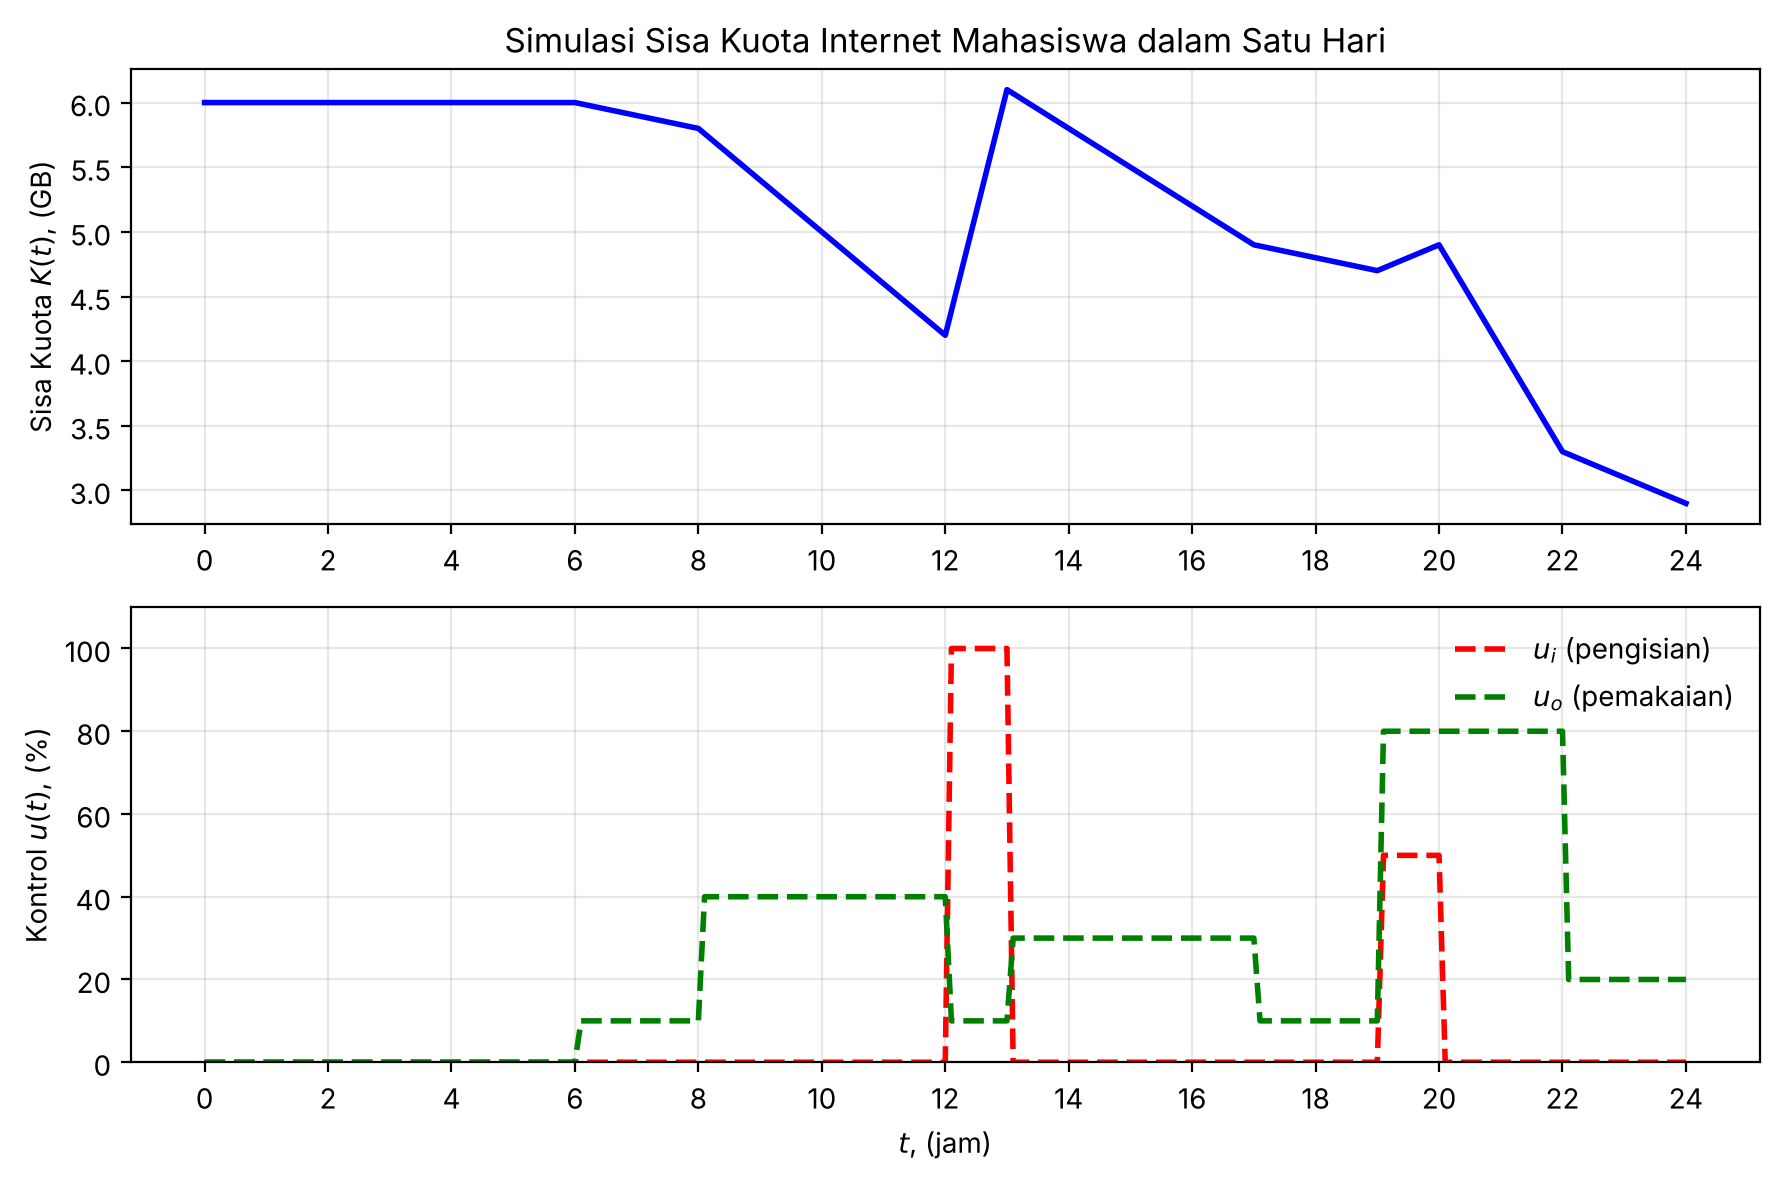

In [8]:
plt.figure(figsize=(9, 6))

plt.subplot(2, 1, 1)
plt.plot(ts, K_odeint, 'b-', linewidth=2)
plt.ylabel(r'Sisa Kuota $K(t)$, (GB)')
plt.title('Simulasi Sisa Kuota Internet Mahasiswa dalam Satu Hari')
plt.xticks(range(0, 25, 2))
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.plot(ts, ui, 'r--', linewidth=2, label=r'$u_i$ (pengisian)')
plt.plot(ts, uo, 'g--', linewidth=2, label=r'$u_o$ (pemakaian)')
plt.ylabel(r'Kontrol $u(t)$, (%)')
plt.xlabel(r'$t$, (jam)')
plt.xticks(range(0, 25, 2))
plt.ylim(0, 110)
plt.legend(frameon=False)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 2.2 Grafik perbandingan ODEINT dan GEKKO

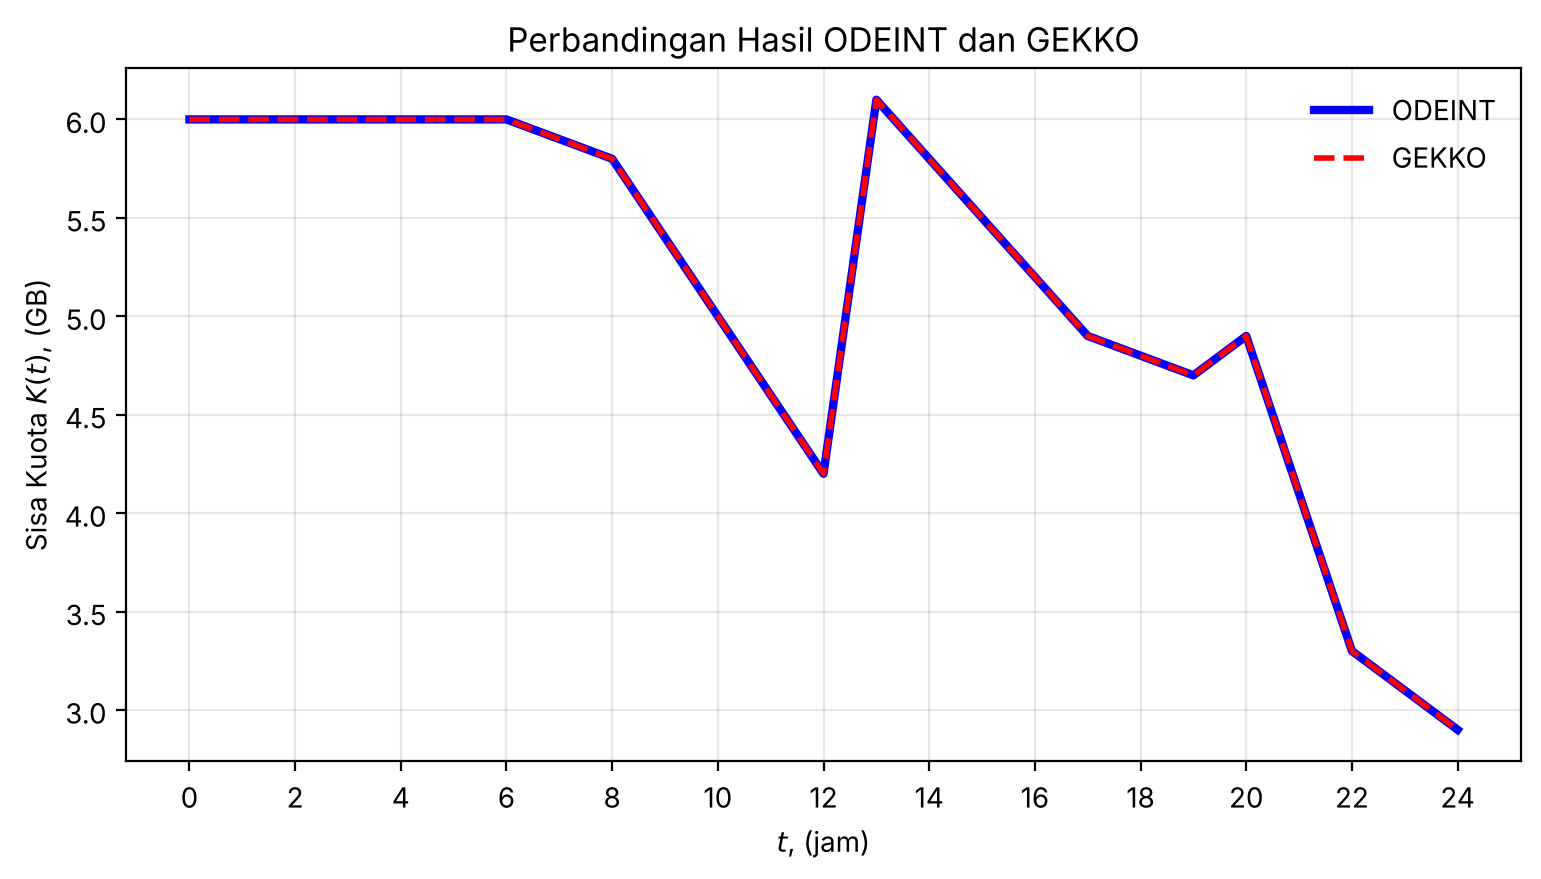

In [9]:
plt.figure(figsize=(9, 4.5))
plt.plot(ts, K_odeint, 'b-', linewidth=3, label='ODEINT')
plt.plot(ts, K_gekko, 'r--', linewidth=2, label='GEKKO')
plt.xlabel(r'$t$, (jam)')
plt.ylabel(r'Sisa Kuota $K(t)$, (GB)')
plt.title('Perbandingan Hasil ODEINT dan GEKKO')
plt.xticks(range(0, 25, 2))
plt.grid(True, alpha=0.3)
plt.legend(frameon=False)
plt.show()

### 2.3 Grafik pengaruh koefisien pemakaian

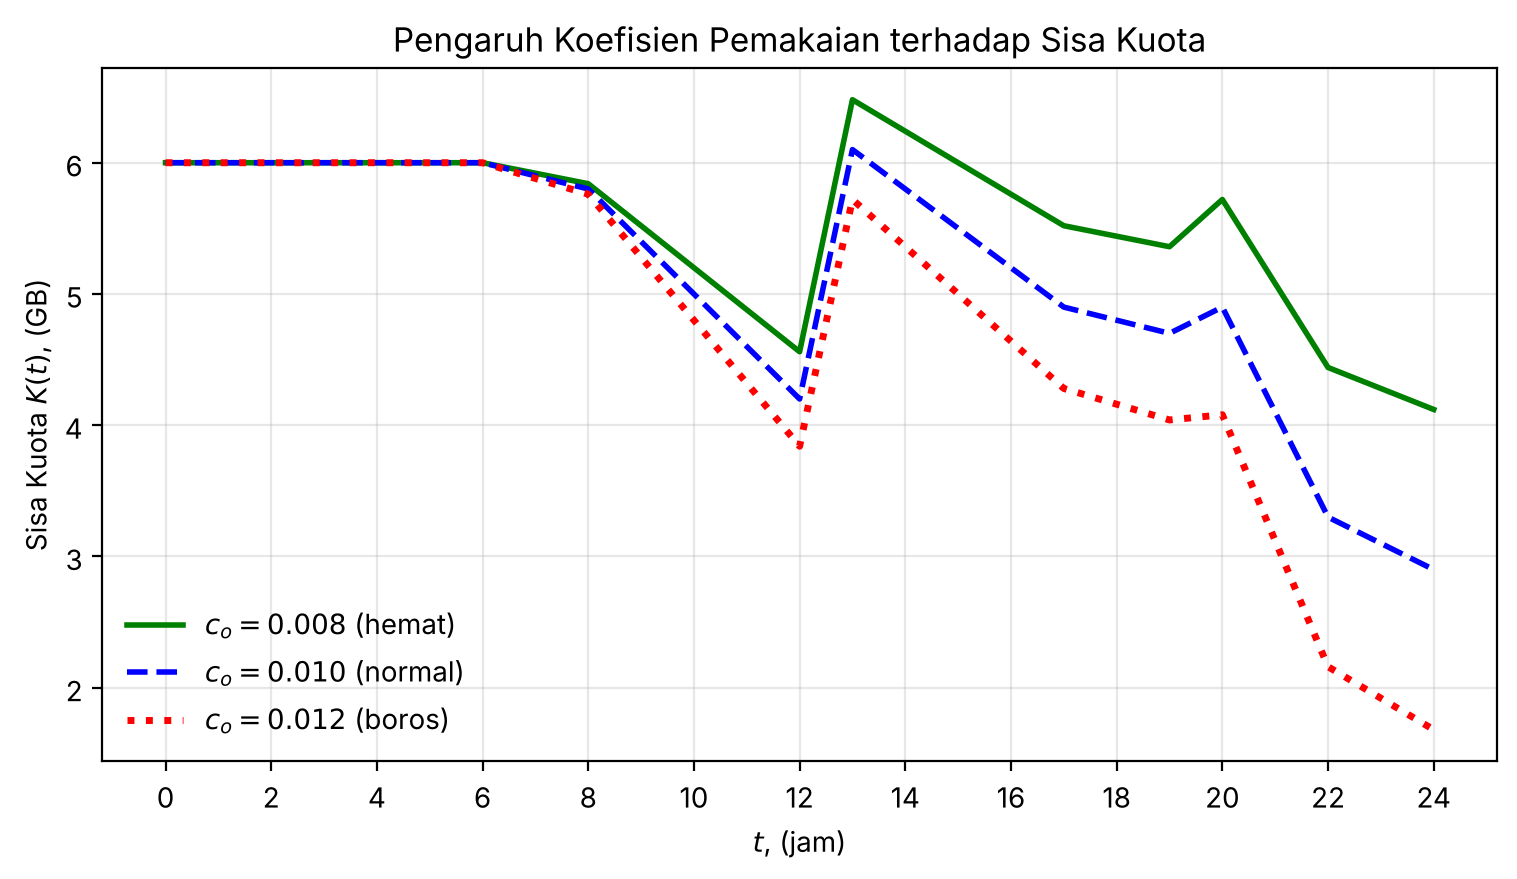

Sisa kuota akhir hari:
co = 0.008 : 4.12 GB
co = 0.010 : 2.9 GB
co = 0.012 : 1.68 GB
Sisa kuota minimum (co = 0.012): 1.68 GB


In [10]:
def simulasi(co_nilai):
    Kx = np.zeros(n)
    Kx[0] = K0
    Kn = K0
    for i in range(1, n):
        y = odeint(kuota, Kn, [ts[i-1], ts[i]], args=(ci, co_nilai, ui[i], uo[i]))
        Kn = y[-1][0]
        Kx[i] = Kn
    return Kx

K1 = simulasi(0.008)
K2 = simulasi(0.010)
K3 = simulasi(0.012)

plt.figure(figsize=(9, 4.5))
plt.plot(ts, K1, 'g-',  linewidth=2, label=r'$c_o=0.008$ (hemat)')
plt.plot(ts, K2, 'b--', linewidth=2, label=r'$c_o=0.010$ (normal)')
plt.plot(ts, K3, 'r:',  linewidth=2.5, label=r'$c_o=0.012$ (boros)')
plt.xlabel(r'$t$, (jam)')
plt.ylabel(r'Sisa Kuota $K(t)$, (GB)')
plt.title('Pengaruh Koefisien Pemakaian terhadap Sisa Kuota')
plt.xticks(range(0, 25, 2))
plt.grid(True, alpha=0.3)
plt.legend(frameon=False)
plt.show()

print("Sisa kuota akhir hari:")
print("co = 0.008 :", round(K1[-1], 3), "GB")
print("co = 0.010 :", round(K2[-1], 3), "GB")
print("co = 0.012 :", round(K3[-1], 3), "GB")
print("Sisa kuota minimum (co = 0.012):", round(K3.min(), 3), "GB")

## 3. Kesimpulan

1. Sisa kuota internet dapat dimodelkan dengan persamaan diferensial orde satu $dK/dt = c_i u_i - c_o u_o$.
2. Hasil simulasi ODEINT dan GEKKO sama dengan perhitungan manual, sehingga model dinyatakan valid.
3. Aktivitas streaming malam hari adalah penyumbang pemakaian terbesar dalam skenario ini, sehingga mengurangi streaming atau memakai wifi pada jam tersebut paling efektif untuk menghemat kuota. Pengisian paket tambahan di waktu yang tepat dapat mencegah kuota habis.